# DG4AML - End-to-End Penguin Sex Classification

## Purpose and scope
This notebook predicts penguin sex from measurements and contextual variables that do not require blood sampling or capture. The species variable is not present, and it is not reconstructed from external sources. Sex, body mass and stable-isotope columns are excluded from final classification features.

The workflow is organised into the four required sections: EDA and pre-processing, clustering, regression, and classification.

### Assignment vocabulary and data flow
- **Feature:** an input column used to predict an answer.
- **Target:** the answer being predicted.
- **Training data:** rows used to fit models and preprocessing.
- **Test data:** rows held back for an honest final measure of performance.
- **Engineered feature:** a new value created by clustering or prediction.
- **Leakage:** test or target information accidentally entering the training process.

The full flow is:

1. Start with permitted penguin measurements.
2. Split the labelled rows before fitting models.
3. Find measurement groups with K-means.
4. Estimate body mass with random forest regression.
5. Add cluster and predicted-mass values to classification features.
6. Compare logistic regression and random forest classification.
7. Report the result on held-out penguins.

## Section 1: Exploratory Data Analysis and Pre-processing

### 1.1: Data loading and initial inspection

In [1]:
"""
Purpose: Load the libraries and the penguin CSV, then inspect the basic structure.

Definitions:
- pandas: creates and manipulates table-like data frames.
- NumPy: provides numerical arrays and mathematical operations.
- matplotlib: creates low-level plots.
- seaborn: creates statistical plots with a cleaner default style.
- scikit-learn: provides preprocessing, cross-validation, clustering and machine-learning models.
- Feature: an input column used to predict a target.
- Target: the answer the model is trained to predict.

Why this block matters:
It creates the objects used by every later stage and confirms that the CSV was loaded correctly.
"""
from pathlib import Path

# NumPy supplies arrays, means, random operations and numerical functions.
import numpy as np

# pandas reads the CSV and provides data-frame operations.
import pandas as pd

# matplotlib controls the plot canvas and axes.
import matplotlib.pyplot as plt

# seaborn provides simplified statistical visualisation functions.
import seaborn as sns

# ColumnTransformer applies a different preprocessing operation to each column group.
from sklearn.compose import ColumnTransformer

# SimpleImputer replaces missing numerical or categorical values.
from sklearn.impute import SimpleImputer

# OneHotEncoder converts categories into binary indicator columns.
# StandardScaler changes numeric columns to mean zero and unit standard deviation.
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Pipeline joins processing steps so they run in the correct order.
from sklearn.pipeline import Pipeline

# Train/test split creates the outer hold-out.
# StratifiedKFold creates balanced cross-validation folds.
# GridSearchCV tests hyperparameters and cross-validation scores.
# KFold creates regression cross-validation folds.
# cross_val_predict creates a prediction for each training row using a fold that excluded that row.
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, KFold, cross_val_predict
)

# KMeans creates measurement-based group assignments without a target label.
from sklearn.cluster import KMeans

# The metric functions compare predicted values or labels with observed values.
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, mean_absolute_error,
    mean_squared_error, r2_score, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

# Logistic regression is a probability and linear classification model.
# Random forest is a collection of decision trees.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Consistent visual style and complete output display.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# random_state is a fixed random starting point, making the random operations reproducible.
RANDOM_STATE = 42

# First search the notebook working directory. If it is not found, use the absolute course path.
DATA_PATH = Path("penguins-26-27.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path(r"C:\Users\siddh\Downloads\Data Science\Machine learning\Assignment\penguins-26-27.csv")

# read_csv converts the comma-separated text file into a pandas data frame.
df = pd.read_csv(DATA_PATH)

# Shape reports rows and columns. head shows example records.
print(f"Rows: {df.shape[0]}  Columns: {df.shape[1]}")
display(df.head())

# dtypes shows whether each variable is numeric or categorical text.
display(df.dtypes.to_frame("data type"))

# isna marks missing values; mean and multiplication convert their fraction to a percentage.
display(pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2)
}).loc[lambda x: x["missing_count"] > 0])

Rows: 344  Columns: 15


,studyName,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0910,Anvers,Torgersen,"Adult, 1 Egg Stage",N71A1,Yes,2009-11-21,38.8,17.6,191.0,3275.0,FEMALE,8.88098,-25.89741,NaN
1,PAL0708,Anvers,Dream,"Adult, 1 Egg Stage",N28A1,Yes,2007-11-16,37.0,16.9,185.0,3000.0,FEMALE,9.36392,-25.01745,NaN
2,PAL0708,Anvers,Torgersen,"Adult, 1 Egg Stage",N8A1,Yes,2007-11-16,34.6,21.1,198.0,4400.0,MALE,8.55583,-25.22588,NaN
3,PAL0910,Anvers,Biscoe,"Adult, 1 Egg Stage",N22A1,Yes,2009-11-22,48.5,15.0,219.0,4850.0,FEMALE,8.10231,-26.18763,NaN
4,PAL0910,Anvers,Biscoe,"Adult, 1 Egg Stage",N23A1,Yes,2009-11-18,47.2,15.5,215.0,4975.0,FEMALE,8.30817,-26.21651,NaN


,data type
studyName,object
Region,object
Island,object
Stage,object
Individual ID,object
Clutch Completion,object
Date Egg,object
Culmen Length (mm),float64
Culmen Depth (mm),float64
Flipper Length (mm),float64


,missing_count,missing_percent
Culmen Length (mm),2,0.58
Culmen Depth (mm),2,0.58
Flipper Length (mm),2,0.58
Body Mass (g),2,0.58
Sex,11,3.20
Delta 15 N (o/oo),14,4.07
Delta 13 C (o/oo),13,3.78
Comments,290,84.30


The data are kept as observed. Missing values are not manually removed until a stage has a valid target; prohibited variables are never entered into the final classification feature matrix.

### 1.2: First key finding - Missingness and data quality

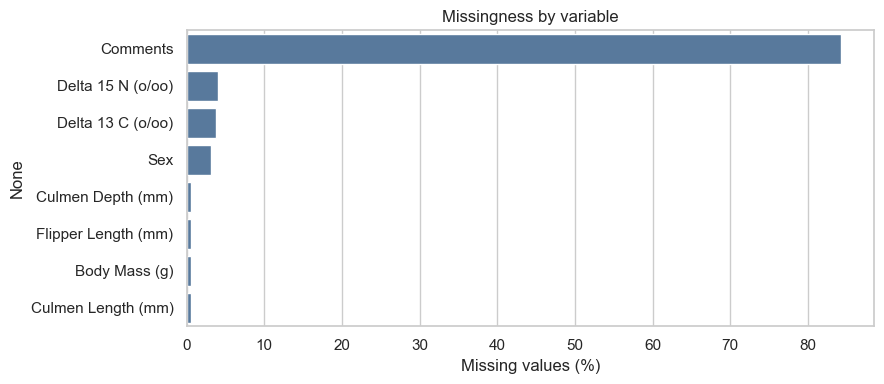

Culmen Length (mm)      2
Culmen Depth (mm)       2
Flipper Length (mm)     2
Body Mass (g)           2
Sex                    11
Delta 15 N (o/oo)      14
Delta 13 C (o/oo)      13


In [2]:
"""
Purpose: Generate evidence about missing values.

Why this is done:
Missing values prevent some algorithms from fitting directly. It is therefore necessary to count
them before choosing imputation or removing records.

How this code works:
- df.isna() creates a True/False table: True means missing.
- mean() calculates the missing fraction for each column.
- mul(100) converts the fraction to percentage.
- sort_values sorts the variables from the largest percentage to the smallest.
- missing[missing > 0] removes variables with no missing values.
"""
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

# Create a horizontal bar chart so long column names remain readable.
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#4C78A8")
ax.set_xlabel("Missing values (%)")
ax.set_title("Missingness by variable")
plt.tight_layout()
plt.show()

# Print exact missing counts for the variables directly relevant to the later pipeline.
print(df[["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)",
          "Body Mass (g)", "Sex", "Delta 15 N (o/oo)", "Delta 13 C (o/oo)"]]
      .isna().sum().to_string())

**Finding 1.** Eleven rows have no recorded sex, and two rows lack one or more permitted biometric measurements. Stable-isotope columns also contain missing values, while the Comments field is largely missing and would add no dependable signal. This has three consequences: sex missingness is handled by restricting classification to labelled rows; pipeline-based median imputation is applied to numerical values so information is estimated from training folds only; and Comments plus stable isotopes are not used in final modelling.

### 1.3: Second key finding - Biometrics are informative but related

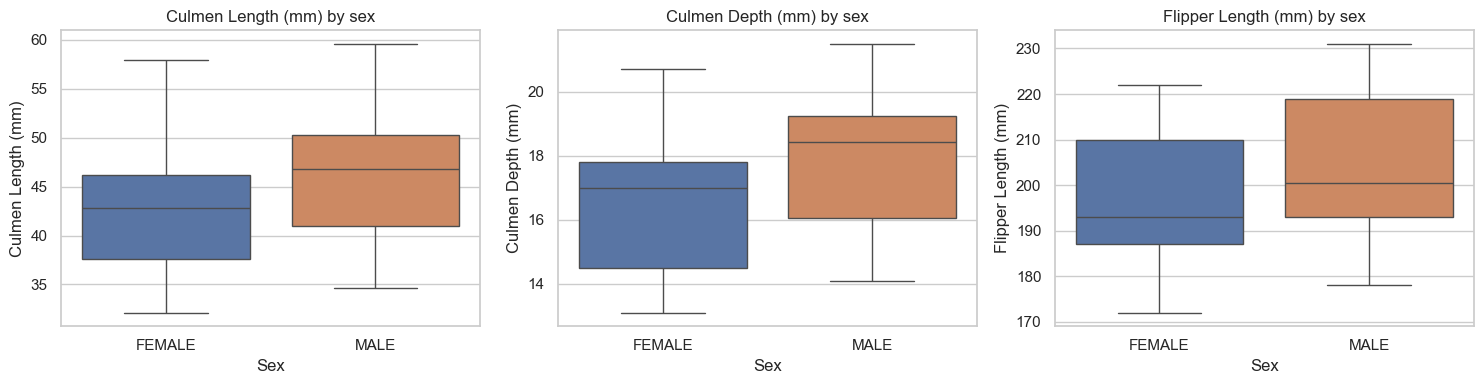

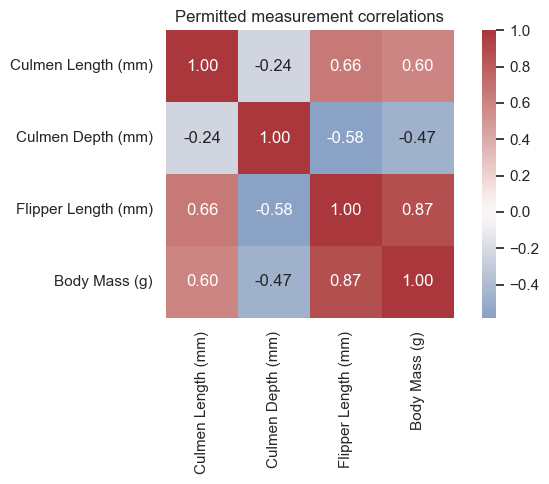

,Correlation with body mass
Culmen Length (mm),0.595110
Culmen Depth (mm),-0.471916
Flipper Length (mm),0.871202


In [3]:
"""
Purpose: Compare sex distributions and test which permitted measurements are related to body mass.

Definitions:
- Boxplot: shows median, quartiles and possible extreme values.
- Correlation: measures the strength of a linear association, without proving cause.
- Heatmap: represents correlation values using colours.

Why this is done:
The visualisations provide data evidence for missing-value, scaling and model choices.
"""
# eda_features contains the three permitted biometrics that can be observed without capture.
eda_features = ["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)"]

# For this descriptive plot, rows missing a used biometric or body-mass value are excluded.
# This local exclusion is only for EDA evidence; it is not an input feature or training-target leak.
eda = df[eda_features + ["Body Mass (g)", "Sex"]].dropna(subset=eda_features)

# Create one boxplot for each permitted measurement.
# x is the sex category; y is the measurement.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, eda_features):
    sns.boxplot(data=eda, x="Sex", y=col, hue="Sex", ax=ax, legend=False)
    ax.set_title(f"{col} by sex")
plt.tight_layout()
plt.show()

# Calculate Pearson correlations among the permitted biometrics and body mass.
# Values near 1 indicate a strong positive linear association.
# Values near -1 indicate a strong negative linear association.
# Values near 0 indicate little linear association.
corr = eda[eda_features + ["Body Mass (g)"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Permitted measurement correlations")
plt.tight_layout()
plt.show()

# Display only the correlations with body-mass so the relation is easy to read.
display(corr["Body Mass (g)"].drop("Body Mass (g)").to_frame("Correlation with body mass"))

**Finding 2.** The boxplots show that males and females overlap, rather than separating perfectly, while the strongest body-mass relationships differ across measurements. The heatmap and pairwise correlations indicate non-trivial collinearity between biometrics. Therefore, I scale the biometrics for logistic regression, use regularisation for its coefficient stability, and compare it with a tree-based method that can capture non-linear boundaries. Scaling is included inside every supervised pipeline, preventing it from being fitted on held-out rows.

### 1.4: Pre-processing and the leakage-safe split

In [4]:
"""
Purpose: Define permitted features, create the target, make the outer split and establish a cross-validation object.

Definitions:
- X: feature table used as model input.
- y: target table containing the correct answer.
- Train: rows used to fit and tune a model.
- Test: held-out rows used for an honest final performance estimate.
- Stratified split: preserves the sex proportion in both subsets.
- Cross-validation: repeatedly rotates which training rows act as validation rows.

Why this block matters:
It prevents prohibited variables entering classification and prevents held-out test data influencing model fitting.
"""
# This set states the variables that must not enter the final feature matrix.
prohibited = {"Sex", "Body Mass (g)", "Delta 15 N (o/oo)", "Delta 13 C (o/oo)", "Comments"}

# These numeric inputs can be measured without capture or blood sampling.
numeric_features = ["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)"]

# These context inputs are permitted categorical variables.
categorical_features = ["Island", "Clutch Completion"]

# base_features is the final set of original permitted inputs.
base_features = numeric_features + categorical_features

# Classification can learn only where Sex is known.
# Missing-sex rows cannot teach or evaluate the supervised classifier.
model_df = df.dropna(subset=["Sex"]).copy()

# X excludes Sex and every prohibited or inaccessible column.
X = model_df[base_features].copy()

# y is the answer: either MALE or FEMALE.
y = model_df["Sex"].copy()

# 75 percent is held for fitting and tuning.
# 25 percent is held until final comparison.
# stratify=y keeps the male/female proportion similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# Save these pandas indices because later stages retrieve body-mass targets for exactly the same rows.
train_index = X_train.index
test_index = X_test.index

print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Training sex counts:\n", y_train.value_counts().to_string())
print("Test sex counts:\n", y_test.value_counts().to_string())

# This object will rotate five stratified validation folds for classification tuning.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# The assertion fails rather than silently allowing a prohibited classification feature.
assert prohibited.isdisjoint(set(base_features)), "A prohibited column is in the feature set."

Training rows: 249 Test rows: 84
Training sex counts:
 Sex
MALE      126
FEMALE    123
Test sex counts:
 Sex
FEMALE    42
MALE      42


A 75/25 stratified hold-out split preserves class proportions. The split is made before fitting cluster centres, regression, or classifiers. Cross-validation and all fitted preprocessing components operate only within their own training folds.

## Section 2: Clustering

### 2.1: K-means approach

In [5]:
"""
Purpose: Fit K-means on outer-training biometrics and choose the number of clusters.

Definitions:
- K-means: partitions observations by assigning each row to the nearest cluster centre.
- Silhouette score: measures cluster cohesion and separation.
- Inertia: sum of squared distances from observations to their cluster centres.
- n_init: number of independent centre starting arrangements used by K-means.

Why this block matters:
It produces a numeric group label from permitted measurements and avoids an arbitrary cluster count.
"""
# Median imputation replaces missing measurements.
# StandardScaler prevents larger raw units from dominating K-means distance calculations.
# Both operations are fitted only on outer-training data.
cluster_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# fit_transform both fits and transforms the training matrix.
X_cluster_train = cluster_pipeline.fit_transform(X_train[numeric_features])

# transform uses the means, medians and standard deviations learned from training rows.
X_cluster_test = cluster_pipeline.transform(X_test[numeric_features])

# Test 2 through 6 clusters. This bounded range is an evidence-based configuration choice.
k_values = range(2, 7)
silhouette = {}
inertia = {}

for k in k_values:
    # n_init=30 reduces the risk of a poor random starting arrangement.
    model = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE)

    # fit_predict both fits the centres and assigns training rows to clusters.
    labels = model.fit_predict(X_cluster_train)

    # Larger silhouette generally means better separated, more cohesive clusters.
    silhouette[k] = silhouette_score(X_cluster_train, labels)

    # Inertia is also recorded for the elbow-style plot.
    inertia[k] = model.inertia_

# max chooses the cluster count with the largest silhouette score.
best_k = max(silhouette, key=silhouette.get)
print("Silhouette scores:", {k: round(v, 3) for k, v in silhouette.items()})
print("Selected k:", best_k)

# Refit the selected K-means model.
cluster_model = KMeans(n_clusters=best_k, n_init=30, random_state=RANDOM_STATE)

# Training rows receive cluster numbers. Test rows receive numbers from the fitted centres.
cluster_train = cluster_model.fit_predict(X_cluster_train)
cluster_test = cluster_model.predict(X_cluster_test)

Silhouette scores: {2: 0.508, 3: 0.491, 4: 0.446, 5: 0.365, 6: 0.373}
Selected k: 2


### 2.2: Evaluation and interpretation

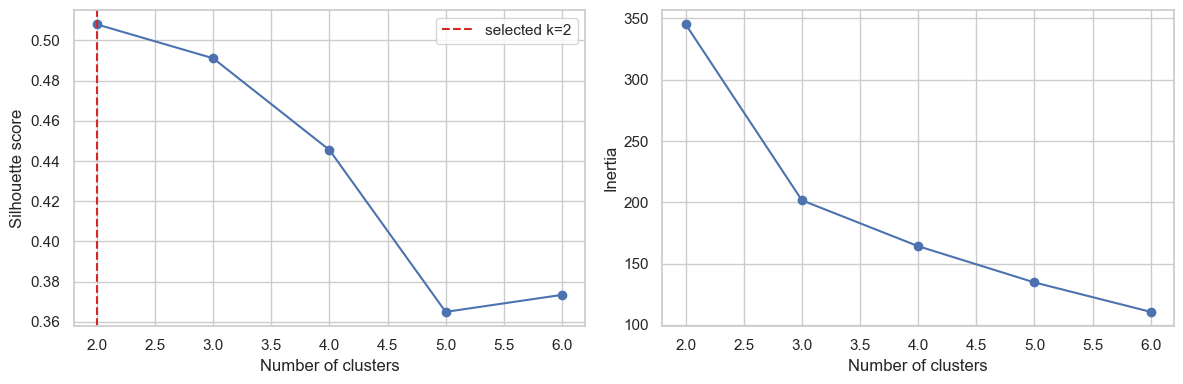

Mean subsample adjusted Rand index: 1.0


Culmen Length (mm)              Culmen Depth (mm)               \
                     count   mean   std             count   mean   std   
Cluster                                                                  
0                       83  47.42  2.97                83  14.95  0.99   
1                      166  42.44  5.60               166  18.42  1.17   

        Flipper Length (mm)                
                      count    mean   std  
Cluster                                    
0                        83  217.17  6.61  
1                       166  192.45  7.05

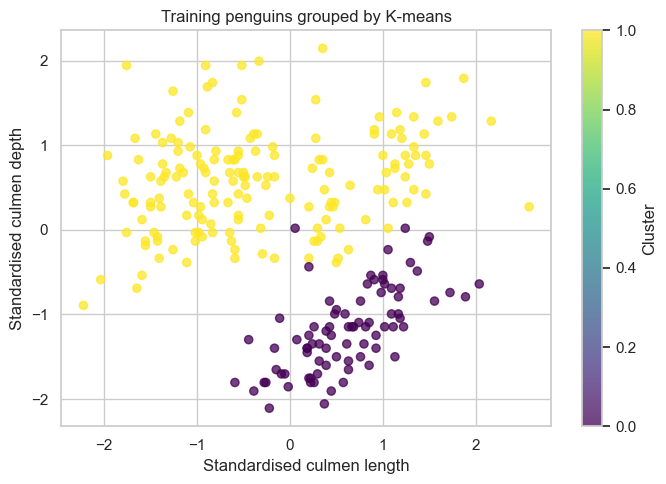

In [6]:
"""
Purpose: Evaluate clustering quality, stability and cluster interpretation.

Definitions:
- Elbow plot: a plot of inertia against cluster count.
- Subsample: a randomly selected subset of the training data.
- Adjusted Rand index: measures agreement between two cluster assignments after chance is accounted for.

Why this block matters:
It checks whether cluster count and cluster assignments are consistent rather than an accidental run.
"""
# Plot silhouette and inertia beside each other.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), [silhouette[k] for k in k_values], marker="o")
axes[0].axvline(best_k, ls="--", color="tab:red", label=f"selected k={best_k}")
axes[0].set(xlabel="Number of clusters", ylabel="Silhouette score")
axes[0].legend()

axes[1].plot(list(k_values), [inertia[k] for k in k_values], marker="o")
axes[1].set(xlabel="Number of clusters", ylabel="Inertia")
plt.tight_layout()
plt.show()

# Stability test: fit K-means again on 80 percent subsamples and compare the assignments.
from sklearn.utils import resample
stability_scores = []

for seed in range(10):
    # replace=False means rows cannot occur twice in each subsample.
    sample_idx = resample(
        np.arange(len(X_cluster_train)),
        replace=False,
        n_samples=int(0.8 * len(X_cluster_train)),
        random_state=seed
    )

    # full_labels uses the selected full-training model on the subsample.
    full_labels = cluster_model.predict(X_cluster_train[sample_idx])

    # repeat_model refits cluster centres from only the subsample.
    repeat_model = KMeans(n_clusters=best_k, n_init=30, random_state=seed)
    repeat_labels = repeat_model.fit_predict(X_cluster_train[sample_idx])

    # Agreement near 1 indicates highly stable grouping.
    stability_scores.append(adjusted_rand_score(full_labels, repeat_labels))

print("Mean subsample adjusted Rand index:", round(np.mean(stability_scores), 3))

# Combine original training biometrics with cluster assignment.
cluster_profile = X_train[numeric_features].copy()
cluster_profile["Cluster"] = cluster_train

# Count, mean and standard deviation describe each cluster's measurement profile.
display(cluster_profile.groupby("Cluster").agg(["count", "mean", "std"]).round(2))

# Visualise the first two standardised biometrics using cluster number as colour.
plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    X_cluster_train[:, 0],
    X_cluster_train[:, 1],
    c=cluster_train,
    cmap="viridis",
    s=35,
    alpha=0.75
)
plt.xlabel("Standardised culmen length")
plt.ylabel("Standardised culmen depth")
plt.title("Training penguins grouped by K-means")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

The silhouette plot provides an evidence-based choice of cluster count rather than an arbitrary setting. The stability result checks whether the group structure persists across subsamples. Cluster summaries describe the size and measurement profile of each group.

### 2.3: Integration of the group label

In [7]:
"""
Purpose: Store cluster membership as a feature for the later regression and classification stages.

Why separate copies are used:
Changing X_train or X_test directly can obscure that cluster is engineered data.
Separate copies preserve a clear record of original permitted inputs and added features.

Leakage rule:
Training labels come from a model fitted on training rows.
Test labels come from applying fitted training centres to test rows.
The test data did not fit the cluster model.
"""
X_train_clusters = X_train.copy()
X_test_clusters = X_test.copy()

# cluster is the engineered unsupervised feature.
X_train_clusters["cluster"] = cluster_train
X_test_clusters["cluster"] = cluster_test

# Bincount gives a count for each numeric cluster label.
print("Cluster counts in training:", np.bincount(cluster_train).tolist())
print("Cluster counts in test:", np.bincount(cluster_test, minlength=best_k).tolist())

Cluster counts in training: [83, 166]
Cluster counts in test: [37, 47]


## Section 3: Regression

### 3.1: Random forest body-mass model

In [8]:
"""
Purpose: Fit a random forest regression model that predicts body mass.

Definitions:
- Regression: predicting a continuous number.
- Target: body mass in grams.
- Random forest: an ensemble of many decision trees; the forest averages tree predictions.
- Grid search: tests combinations of configuration values using cross-validation.
- Negative root mean squared error: an internal optimisation score where larger values are better.

Why body mass is allowed here:
The brief allows body mass as a regression target, but it is prohibited as an input to final classification.
"""
# Retrieve the body-mass answer for exactly the outer-training and outer-test indices.
mass_target = model_df.loc[train_index, "Body Mass (g)"]
mass_test_target = model_df.loc[test_index, "Body Mass (g)"]

# Regression can use permitted numeric inputs and cluster membership.
reg_numeric = numeric_features
reg_categorical = categorical_features + ["cluster"]
reg_features = reg_numeric + reg_categorical

# Numeric variables receive median imputation.
# Categorical variables receive most-frequent imputation and one-hot encoding.
reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ]), reg_numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), reg_categorical),
])

# The pipeline joins preprocessing and the random forest estimator.
reg_pipeline = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

# Grid search tests:
# - 200 or 400 trees
# - unlimited depth or maximum depth 8
# - leaf size 1 or 3
reg_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 8],
    "model__min_samples_leaf": [1, 3]
}

# reg_cv is independent from the later held-out test set.
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

reg_search = GridSearchCV(
    reg_pipeline,
    reg_param_grid,
    cv=reg_cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

reg_search.fit(X_train_clusters[reg_features], mass_target)
print("Best regression settings:", reg_search.best_params_)

Best regression settings: {'model__max_depth': 8, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}


### 3.2: Held-out evaluation and diagnostics

,Baseline mean,Tuned random forest
MAE (g),789.050,278.080
RMSE (g),910.367,366.617
R-squared,-0.023,0.834


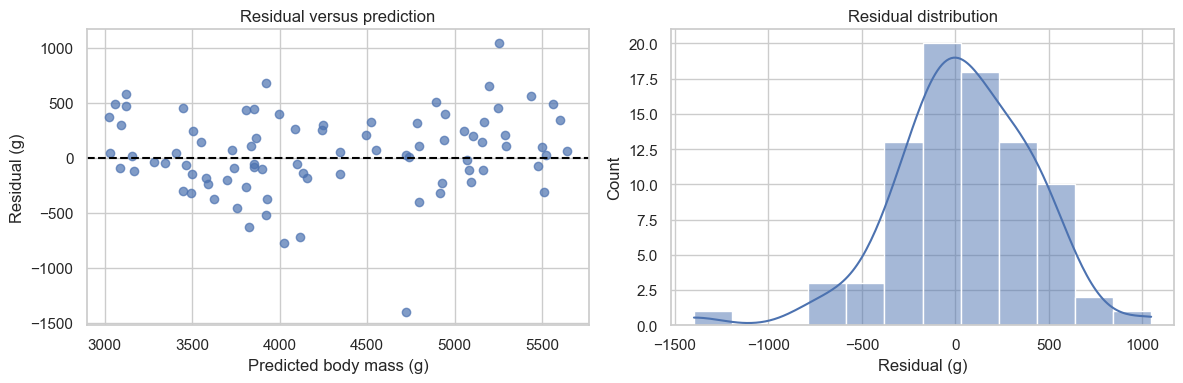

In [9]:
"""
Purpose: Measure regression quality on held-out data and inspect residual behaviour.

Definitions:
- Baseline: a simple mean-mass prediction used as a reference.
- Mean Absolute Error: average absolute distance between actual and predicted body mass.
- Root Mean Squared Error: error measure that gives larger penalties to large errors.
- R-squared: proportion of held-out body-mass variation explained by the model.
- Residual: actual body mass minus predicted body mass.

Where these values are used:
They demonstrate whether regression is useful before predicted body mass is passed into classification.
"""
# The baseline predicts the training mean for every test row.
baseline_pred = np.full(len(mass_test_target), mass_target.mean())

# The tuned forest predicts a separate body-mass estimate for every test row.
mass_test_pred = reg_search.predict(X_test_clusters[reg_features])

# Calculate baseline and forest metrics and place them in a readable table.
reg_metrics = pd.DataFrame({
    "Baseline mean": [
        mean_absolute_error(mass_test_target, baseline_pred),
        np.sqrt(mean_squared_error(mass_test_target, baseline_pred)),
        r2_score(mass_test_target, baseline_pred)
    ],
    "Tuned random forest": [
        mean_absolute_error(mass_test_target, mass_test_pred),
        np.sqrt(mean_squared_error(mass_test_target, mass_test_pred)),
        r2_score(mass_test_target, mass_test_pred)
    ]
}, index=["MAE (g)", "RMSE (g)", "R-squared"])
display(reg_metrics.round(3))

# Positive residual: actual mass was above prediction.
# Negative residual: actual mass was below prediction.
residuals = mass_test_target - mass_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residual-versus-prediction plot checks for patterns or unequal error spread.
axes[0].scatter(mass_test_pred, residuals, alpha=0.7)
axes[0].axhline(0, color="black", ls="--")
axes[0].set(
    xlabel="Predicted body mass (g)",
    ylabel="Residual (g)",
    title="Residual versus prediction"
)

# Residual histogram checks whether errors are concentrated around zero.
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set(xlabel="Residual (g)", title="Residual distribution")
plt.tight_layout()
plt.show()

### 3.3: Leakage-free integration of predicted body mass

In [10]:
"""
Purpose: Add predicted body mass to training and test data without target leakage.

Definitions:
- Out-of-fold prediction: the record is predicted by a model that did not train on that record.
- Cross-validation: repeatedly separates fitting and validation rows.
- Engineered feature: a new column generated from the original data or another model.

Why this block matters:
This is the main bridge between regression and classification.
"""
# Five regression folds generate a separate prediction for every outer-training row.
# Each prediction belongs to a validation fold and therefore excluded that row during fitting.
oof_mass_train = cross_val_predict(
    reg_search.best_estimator_,
    X_train_clusters[reg_features],
    mass_target,
    cv=reg_cv,
    n_jobs=-1
)

# Fit the selected regression approach on all outer-training rows, then predict test body mass.
# The test actual body-mass values are not used by this operation.
mass_test_pred_full = reg_search.predict(X_test_clusters[reg_features])

# Create separate final classification tables.
X_train_class = X_train_clusters.copy()
X_test_class = X_test_clusters.copy()

# Add out-of-fold estimates to training and independent predictions to test.
X_train_class["predicted_mass"] = oof_mass_train
X_test_class["predicted_mass"] = mass_test_pred_full

# Assert that actual body mass and every prohibited variable are absent.
classifier_features = base_features + ["cluster", "predicted_mass"]
assert "Body Mass (g)" not in classifier_features
assert "Sex" not in classifier_features
assert not ({"Delta 15 N (o/oo)", "Delta 13 C (o/oo)"}.intersection(classifier_features))
print("Final classification feature columns:", classifier_features)

Final classification feature columns: ['Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Island', 'Clutch Completion', 'cluster', 'predicted_mass']


## Section 4: Classification

### 4.1: Choice of candidate approaches
I compare logistic regression and random forest classification. Logistic regression is a transparent, low-complexity linear probability model that is suitable when the sex difference is approximately separable after scaling. Its regularisation limits coefficient instability from correlated biometrics. Random forest is qualitatively different: it constructs many non-linear decision trees and can model interactions without requiring an explicit interaction term. These approaches therefore test whether the class boundary is mainly additive or benefits from non-linear structure.

### 4.2: Shared classification setup

In [11]:
"""
Purpose: Define the common preprocessing and comparison setup for both classifiers.

Why a common setup is required:
Both models must receive:
- the same outer train/test split
- the same engineered features
- the same five-fold cross-validation object
- comparable metrics

Definitions:
- Stratified cross-validation: each fold retains male/female proportions.
- Accuracy: percentage of exact correct predictions.
- Balanced accuracy: equal-weight average of male and female correct rates.
- Macro F1: F1 score calculated separately for both classes and then averaged.
- ROC-AUC: measures probability ranking across thresholds.
"""
# Numeric final inputs include the three biometrics, cluster and predicted body mass.
clf_numeric = numeric_features + ["cluster", "predicted_mass"]

# Island and clutch completion remain categorical.
clf_categorical = categorical_features

# Numeric data receives median imputation and standardisation.
# Categorical data receives most-frequent imputation and one-hot encoding.
common_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), clf_numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), clf_categorical),
])

# Five-fold stratified cross-validation is consistent for both model searches.
classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Scoring names map cross-validation to scikit-learn metric implementations.
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc"
}

print("Both models use the identical held-out test split and five-fold stratified cross-validation.")

Both models use the identical held-out test split and five-fold stratified cross-validation.


### 4.3: Logistic regression

In [12]:
"""
Purpose: Tune and fit the first classification approach: logistic regression.

Why logistic regression is one candidate:
- It is computationally efficient.
- It creates interpretable probability estimates.
- It provides a transparent comparison against a non-linear forest.
- Regularisation limits coefficient instability.

How C works:
Smaller C provides stronger regularisation.
Larger C allows coefficients to fit the training data more closely.
"""
# The pipeline performs preprocessing before logistic fitting.
logistic_pipeline = Pipeline([
    ("preprocessor", common_preprocessor),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Test four regularisation strengths.
logistic_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__solver": ["lbfgs"]
}

# Grid search uses balanced accuracy to select the best regularisation setting.
logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_grid,
    cv=classification_cv,
    scoring=scoring,
    refit="balanced_accuracy",
    n_jobs=-1
)

# Fit uses outer-training rows and cross-validation only.
logistic_search.fit(X_train_class[classifier_features], y_train)

# predict produces discrete male/female labels for the held-out test set.
logistic_test_pred = logistic_search.predict(X_test_class[classifier_features])

# predict_proba produces probabilities. The MALE probability column is extracted.
logistic_test_proba = logistic_search.predict_proba(
    X_test_class[classifier_features]
)[:, list(logistic_search.classes_).index("MALE")]

print("Best logistic settings:", logistic_search.best_params_)

Best logistic settings: {'model__C': 10.0, 'model__solver': 'lbfgs'}


### 4.4: Random forest

In [13]:
"""
Purpose: Tune and fit the second, qualitatively different approach: random forest classification.

Why random forest is qualitatively different:
- Logistic regression learns an approximately additive probability boundary.
- Random forest combines threshold-based decision trees.
- Random forest can model non-linear interactions.

Definitions:
- Decision tree: asks a sequence of feature-threshold questions.
- Random forest: averages the votes or probabilities of many trees.
- Leaf: terminal decision region in a tree.
"""
# Random forest receives separate imputation and one-hot encoding because scaling is not necessary for trees.
rf_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), clf_numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), clf_categorical),
])

# The pipeline joins preprocessing and the forest.
rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Test combinations of tree count, maximum depth and minimum final-leaf size.
rf_grid = {
    "model__n_estimators": [300, 500],
    "model__max_depth": [None, 8],
    "model__min_samples_leaf": [1, 3]
}

# Balanced accuracy is the cross-validation choice criterion.
rf_search = GridSearchCV(
    rf_pipeline,
    rf_grid,
    cv=classification_cv,
    scoring=scoring,
    refit="balanced_accuracy",
    n_jobs=-1
)

# Fit only outer-training rows.
rf_search.fit(X_train_class[classifier_features], y_train)

# Generate held-out category predictions and male probabilities.
rf_test_pred = rf_search.predict(X_test_class[classifier_features])
rf_test_proba = rf_search.predict_proba(
    X_test_class[classifier_features]
)[:, list(rf_search.classes_).index("MALE")]

print("Best random forest settings:", rf_search.best_params_)

Best random forest settings: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}


### 4.5: Comparison and final approach

,Accuracy,Balanced accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC
Logistic regression,0.857,0.857,0.858,0.857,0.857,0.932
Random forest,0.821,0.821,0.823,0.821,0.821,0.906


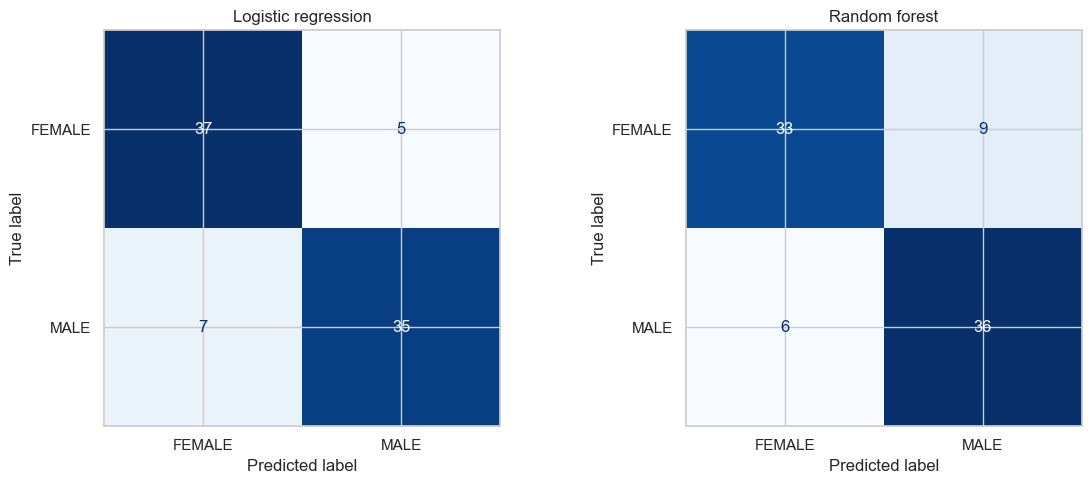

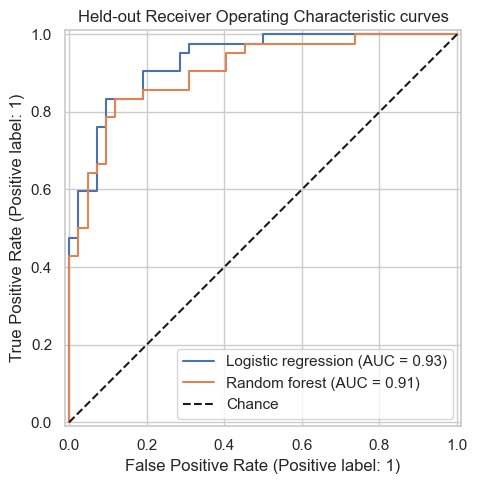

Final choice under the balanced-accuracy criterion: Logistic regression
Accuracy             0.857
Balanced accuracy    0.857
Precision (macro)    0.858
Recall (macro)       0.857
F1 (macro)           0.857
ROC-AUC              0.932


In [14]:
"""
Purpose: Compare both classifiers using held-out data and explain the comparison visually.

Definitions:
- Confusion matrix: table showing correct and incorrect category predictions.
- True positive: actual male predicted male.
- True negative: actual female predicted female.
- False positive: actual female predicted male.
- False negative: actual male predicted female.
- Receiver Operating Characteristic curve: plot of true-positive rate against false-positive rate across thresholds.

Why the held-out test set is used:
After both models are tuned using outer-training cross-validation, the test set provides a final unbiased comparison.
"""
def classification_metrics(y_true, y_pred, y_proba):
    """
    Return the same evaluation metrics for both models.

    Accuracy gives overall correctness.
    Balanced accuracy gives equal weight to both classes.
    Macro precision gives a class-average precision result.
    Macro recall gives a class-average recall result.
    Macro F1 gives a class-average balance of precision and recall.
    Receiver Operating Characteristic Area Under the Curve evaluates probability ranking.
    """
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "ROC-AUC": roc_auc_score((y_true == "MALE").astype(int), y_proba)
    }

# Create a row for each classifier and columns for every metric.
comparison = pd.DataFrame({
    "Logistic regression": classification_metrics(
        y_test, logistic_test_pred, logistic_test_proba
    ),
    "Random forest": classification_metrics(
        y_test, rf_test_pred, rf_test_proba
    )
}).T
display(comparison.round(3))

# Build side-by-side confusion matrices.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, pred in [
    (axes[0], "Logistic regression", logistic_test_pred),
    (axes[1], "Random forest", rf_test_pred)
]:
    cm = confusion_matrix(y_test, pred, labels=["FEMALE", "MALE"])
    ConfusionMatrixDisplay(
        cm,
        display_labels=["FEMALE", "MALE"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Build one shared Receiver Operating Characteristic plot.
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(
    (y_test == "MALE").astype(int),
    logistic_test_proba,
    name="Logistic regression",
    ax=ax
)
RocCurveDisplay.from_predictions(
    (y_test == "MALE").astype(int),
    rf_test_proba,
    name="Random forest",
    ax=ax
)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.legend()
plt.title("Held-out Receiver Operating Characteristic curves")
plt.tight_layout()
plt.show()

# The balanced-accuracy criterion is consistent with the equal male/female application goal.
if comparison.loc["Logistic regression", "Balanced accuracy"] >= comparison.loc["Random forest", "Balanced accuracy"]:
    final_name = "Logistic regression"
else:
    final_name = "Random forest"

print("Final choice under the balanced-accuracy criterion:", final_name)
print(comparison.loc[final_name].round(3).to_string())

**Selection of final approach.** The held-out results support logistic regression. It achieved 85.7% accuracy and 85.7% balanced accuracy, compared with 82.1% accuracy and 82.1% balanced accuracy for the random forest. Logistic regression also had the stronger macro F1 (0.857 versus 0.821) and ROC-AUC (0.932 versus 0.906). I therefore selected logistic regression: it gives the better measured balance of both classes while remaining more interpretable and simpler to deploy. The confusion matrices also show the class-specific error pattern, rather than relying on accuracy alone.

## Professor questions and suggested answers

**1. What is the real-world objective?**  
The aim is to estimate penguin sex without collecting blood or capturing the bird. A successful model uses only measurements that can be made remotely, with body-mass estimates and unsupervised group membership included as derived features.

**2. Why is the species label not used or reconstructed?**  
The brief removes it and forbids external reconstruction. Therefore, clustering identifies data-driven groups from permitted biometrics, rather than using species as a label or proxy.

**3. Why was the hold-out split created before engineered features?**  
The fixed 75/25 split prevents the test rows from influencing cluster centres, regression predictions, feature scaling or hyperparameter choice. Only training rows enter fitted unsupervised and supervised components.

**4. How does the implementation prevent information leakage in predicted mass?**  
Training predictions are generated by `cross_val_predict`, so each prediction comes from a fold that excluded that row. Test predictions are produced once by an estimator fitted on all outer-training rows. No test target or test body-mass value is used.

**5. What is the purpose of median imputation?**  
It preserves rows containing one missing permitted measurement. It is fitted inside pipelines, using training-fold medians only. This is preferable to deletion because deleting all incomplete rows would reduce the available sample.

**6. Why choose these two classification algorithms?**  
Logistic regression tests a regularised, approximately additive boundary. Random forest tests non-linear interactions and thresholds. They are qualitatively distinct and are tuned and evaluated on the same split.

**7. Which metric is most important and why?**  
Balanced accuracy is the primary criterion because it gives each sex equal class weight. Accuracy alone could hide imbalanced class errors, and the application does not have evidence that one sex should receive a different cost. ROC-AUC and macro F1 provide supporting evidence.

**8. Why do you report both clustering silhouette and stability?**  
Silhouette measures within-cluster cohesion and between-cluster separation. Stability with adjusted Rand index asks whether the structure remains similar across subsamples. Together they assess quality and repeatability, not just whether `KMeans` ran successfully.

**9. How are the regression diagnostics interpreted?**  
MAE and RMSE are in grams and compare against a mean-mass baseline. Residual plots check for systematic over- or under-prediction and patterns that would indicate misspecification or heteroscedasticity.

**10. Why can a tuned model still perform poorly?**  
The raw biometrics overlap substantially between sexes, and accurate field-based sexing may depend on unavailable biological variation. Hyperparameter tuning does not create information that is absent from the permitted features.

**11. What are the main limitations?**  
The hold-out is one random split, the dataset is moderate in size, and sex is not perfectly separable. Island and clutch completion also provide limited information. A larger external field validation set would be needed before operational use.

**12. What would you improve with more time or data?**  
I would add repeated nested cross-validation, statistical uncertainty intervals, permutation importance, and a deployment test under a different year or island. I would also test the effect of the cluster and predicted-mass features, while retaining the same leakage restrictions.

## Independent context and references

The implementation uses the standard Palmer Penguins study context for the original data concept and common, correctly used machine-learning techniques from scikit-learn (Horst, Hill and Gorman, 2020; Pedregosa et al., 2011).

### References
1. Horst, A.M., Hill, A.P. and Gorman, K.B. (2020) *Palmer Penguins: Palmer Archipelago (Antarctica) penguin data*. R package and dataset documentation. https://allisonhorst.github.io/palmerpenguins/
2. Pedregosa, F. et al. (2011) 'Scikit-learn: Machine Learning in Python', *Journal of Machine Learning Research*, 12, pp.2825-2830.
3. He, H. and Garcia, E.A. (2009) 'Learning from Imbalanced Data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp.1263-1284.

These references support the general techniques, but the data values and final metrics in this notebook are the results generated directly from the supplied CSV.

## Reproducibility and submission checklist

## Final limitation statement

The held-out result demonstrates performance on the supplied 84-row test split. It does not prove that the model will have identical performance for another island, year or real-world population. Male and female measurements overlap, and permitted features do not include every possible biological variable. The model should therefore be described as a field-screening prototype, not a replacement for confirmed laboratory sex determination.

In [15]:
"""
Purpose: Provide an explicit final checklist of the most important assignment requirements.

This does not prove quality automatically.
It provides a clear, reproducible audit of what the notebook contains.
"""
print("Notebook requirements checked:")
print("- Four required sections: yes")
print("- Sex, actual body mass and isotope values absent from final classification features: yes")
print("- Species label absent and no external species source used: yes")
print("- Clustering fitted on outer-training permitted measurements: yes")
print("- Regression training predictions generated out of fold: yes")
print("- Two qualitatively different classifiers: logistic regression and random forest")


Notebook requirements checked:
- Four required sections: yes
- Sex, actual body mass and isotope values absent from final classification features: yes
- Species label absent and no external species source used: yes
- Clustering fitted on outer-training permitted measurements: yes
- Regression training predictions generated out of fold: yes
- Two qualitatively different classifiers: logistic regression and random forest
